In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime, timedelta

import tensorflow as tf

from helper import fn_plot_tf_hist


In [2]:
data_df=pd.read_csv('weatherHistory.csv')

In [3]:
data_df.head()

,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,Partly cloudy throughout the day.
3,2006-04-01 03:00:00.000 +0200,Partly Cloudy,rain,8.288889,5.944444,0.83,14.1036,269.0,15.8263,0.0,1016.41,Partly cloudy throughout the day.
4,2006-04-01 04:00:00.000 +0200,Mostly Cloudy,rain,8.755556,6.977778,0.83,11.0446,259.0,15.8263,0.0,1016.51,Partly cloudy throughout the day.


In [4]:
data_df.isna().sum().sum()

np.int64(517)

In [5]:
# Convert the string dates to actual datetime objects
data_df['datetime'] = pd.to_datetime(data_df['Formatted Date'], utc=True)

data_df.head(1)


,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary,datetime
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.,2006-03-31 22:00:00+00:00


In [6]:
data_df.columns

Index(['Formatted Date', 'Summary', 'Precip Type', 'Temperature (C)',
       'Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)',
       'Wind Bearing (degrees)', 'Visibility (km)', 'Loud Cover',
       'Pressure (millibars)', 'Daily Summary', 'datetime'],
      dtype='str')

In [7]:
data_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 96453 entries, 0 to 96452
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype              
---  ------                    --------------  -----              
 0   Formatted Date            96453 non-null  str                
 1   Summary                   96453 non-null  str                
 2   Precip Type               95936 non-null  str                
 3   Temperature (C)           96453 non-null  float64            
 4   Apparent Temperature (C)  96453 non-null  float64            
 5   Humidity                  96453 non-null  float64            
 6   Wind Speed (km/h)         96453 non-null  float64            
 7   Wind Bearing (degrees)    96453 non-null  float64            
 8   Visibility (km)           96453 non-null  float64            
 9   Loud Cover                96453 non-null  float64            
 10  Pressure (millibars)      96453 non-null  float64            
 11  Daily Summary             

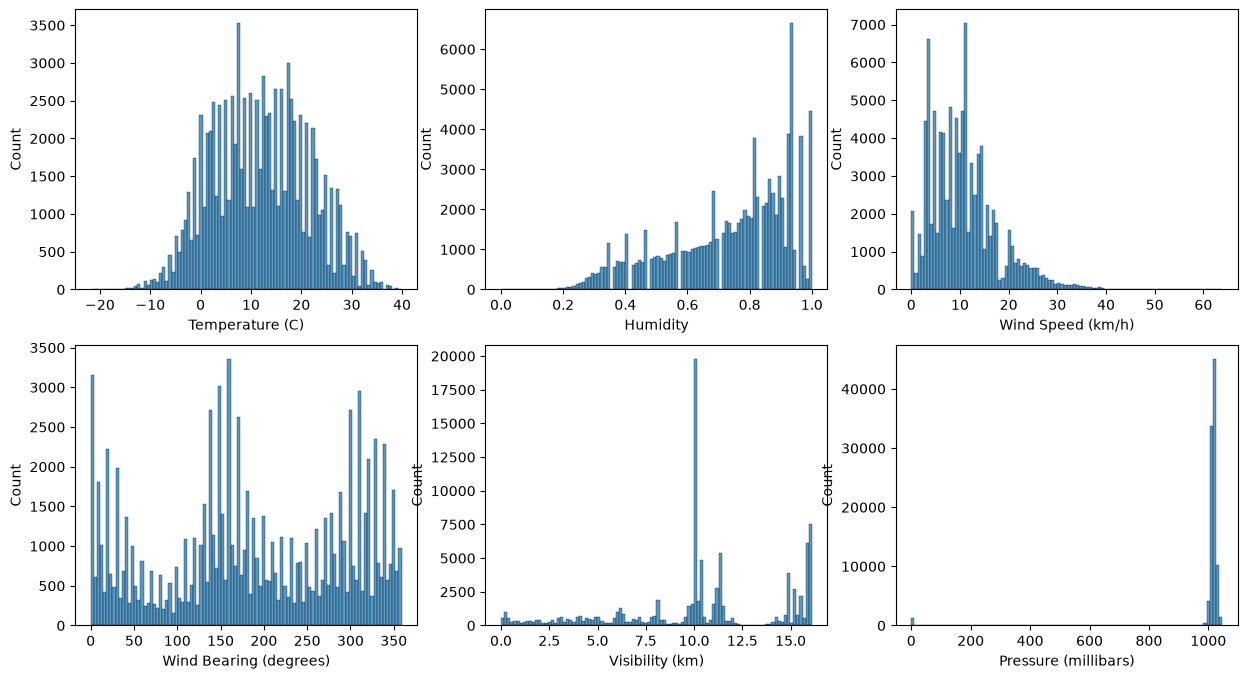

In [8]:
num_cols = ['Temperature (C)', 'Humidity', 'Wind Speed (km/h)',
            'Wind Bearing (degrees)', 'Visibility (km)', 'Pressure (millibars)']
fig,axes=plt.subplots(2,3,figsize=(15,8))
axes=axes.ravel()
for count,col in enumerate(num_cols):
    ax=axes[count]
    sns.histplot(data=data_df,x=col,ax=ax,bins=100)

<Axes: >

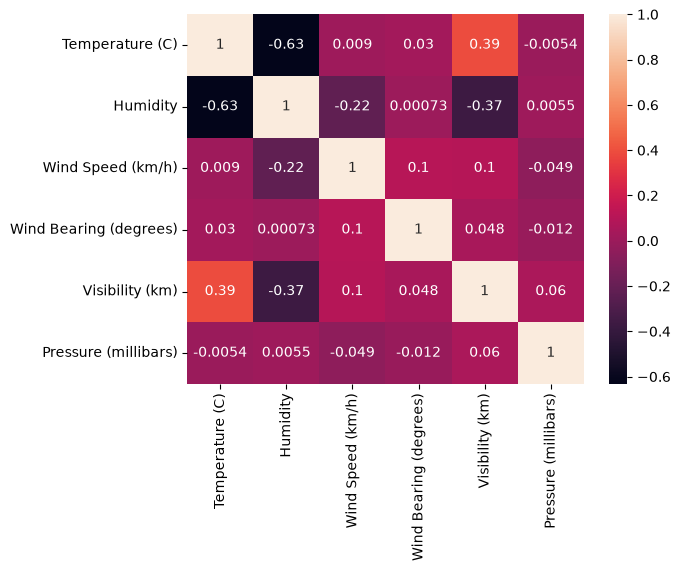

In [9]:
sns.heatmap(data_df[num_cols].corr(),annot=True,)

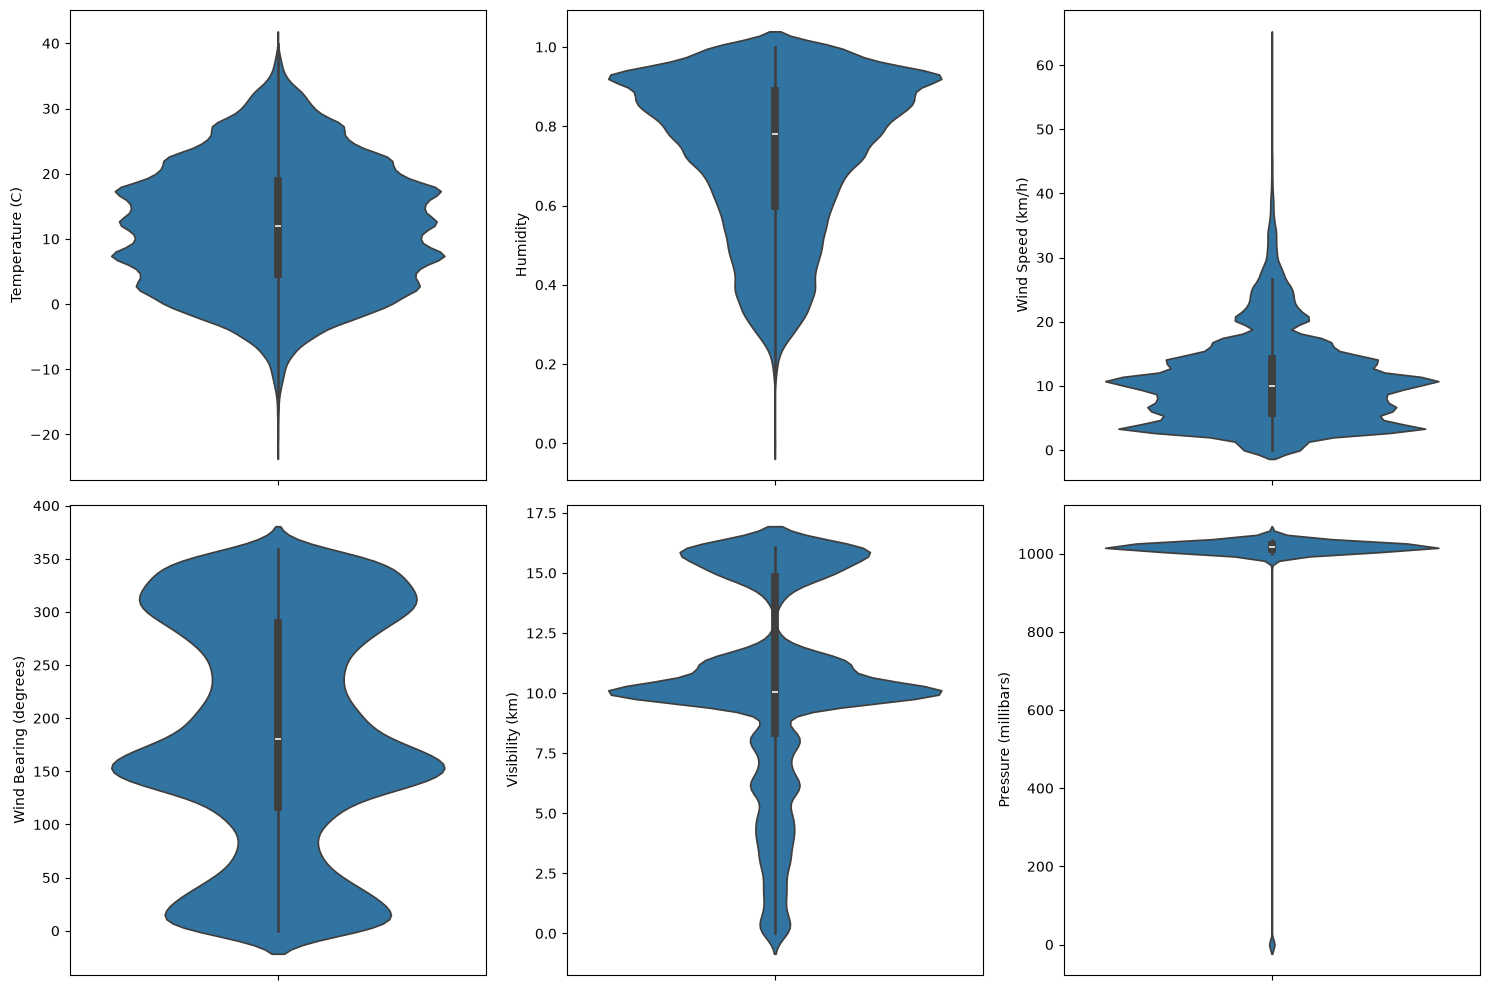

In [10]:


# Initialize a single figure and flatten the axes array
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 10))
axes = axes.ravel()

# Loop through columns and populate each subplot
for count, col in enumerate(num_cols):
    ax = axes[count]
    # Removed 'bins=100' as violin plots do not accept a bins argument
    sns.violinplot(data=data_df, y=col, ax=ax)
    
# Clean up layout spacing and display the final figure
plt.tight_layout()
plt.show()


In [11]:
tmp_df = data_df[['datetime', 'Temperature (C)', 'Humidity', 'Wind Speed (km/h)']]
tmp_df = tmp_df.sort_values('datetime', axis=0, ascending=True)
tmp_df=tmp_df.rename({'Temperature (C)' :'temp', 'Humidity':'hum', 'Wind Speed (km/h)':'wind'},axis=1)
tmp_df = tmp_df.reset_index(drop=True)
tmp_df.head()


,datetime,temp,hum,wind
0,2005-12-31 23:00:00+00:00,0.577778,0.89,17.1143
1,2006-01-01 00:00:00+00:00,1.161111,0.85,16.6152
2,2006-01-01 01:00:00+00:00,1.666667,0.82,20.2538
3,2006-01-01 02:00:00+00:00,1.711111,0.82,14.4900
4,2006-01-01 03:00:00+00:00,1.183333,0.86,13.9426


<Axes: xlabel='datetime'>

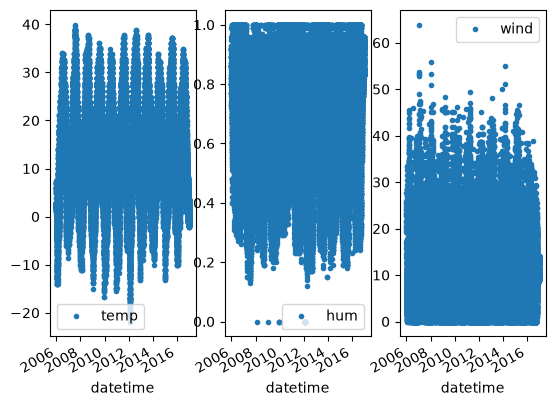

In [12]:
fig, axes = plt.subplots(1,3)
ax = axes[0]
tmp_df.plot(x='datetime', y='temp', style='.',ax= ax)
ax = axes[1]
tmp_df.plot(x='datetime', y='hum', style='.',ax= ax)
ax = axes[2]
tmp_df.plot(x='datetime', y='wind', style='.',ax= ax)

In [13]:
h_units = 100
input_shape = (1,10000)

model = tf.keras.Sequential()
model.add(tf.keras.layers.Input(shape = input_shape))
model.add(tf.keras.layers.SimpleRNN(units = h_units, activation = 'tanh'))
model.add(tf.keras.layers.Dense(1))

In [14]:
Wax = model.get_weights()[0].shape
Waa = model.get_weights()[1].shape
baa = model.get_weights()[2].shape
Way = model.get_weights()[3].shape
bay = model.get_weights()[4].shape

print(f'Wax: {Wax}; Waa: {Waa}; baa: {baa}; Way: {Way}; bay: {bay}')

Wax: (10000, 100); Waa: (100, 100); baa: (100,); Way: (100, 1); bay: (1,)


In [15]:
time_step = 24
y_idx = np.arange(time_step, tmp_df.shape[0], time_step)
y_idx
y_df = tmp_df.iloc[y_idx]


In [16]:
X_df=tmp_df.iloc[range(len(y_df)*time_step)]
X_df.shape

(96432, 4)

In [17]:
X=np.reshape(X_df['temp'].to_numpy(), (y_df.shape[0], time_step))
X.shape, y_df.shape

((4018, 24), (4018, 4))

In [18]:
X_temp = np.reshape(X_df['temp'].to_numpy(), (y_df.shape[0], time_step))
X_hum = np.reshape(X_df['hum'].to_numpy(), (y_df.shape[0], time_step))
X_wind = np.reshape(X_df['wind'].to_numpy(), (y_df.shape[0], time_step))
X_temp.shape, X_hum.shape, X_wind.shape, y_df.shape


((4018, 24), (4018, 24), (4018, 24), (4018, 4))

In [19]:
X_temp = X_temp[:, :23]
X_hum = X_hum[:, :23]
X_wind = X_wind[:, :23]


In [20]:
X_data = np.stack((X_temp, X_hum, X_wind), axis = 2)
X_data.shape

(4018, 23, 3)

In [21]:
split = int(y_df.shape[0] * (1- 0.2))

X_train = X_data[:split]
X_test = X_data[split:]
y_train = y_df['temp'].to_numpy()[:split]
y_test = y_df['temp'].to_numpy()[split:]

In [22]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(3214, 23, 3) (804, 23, 3) (3214,) (804,)


In [23]:
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
train_ds = train_ds.cache()
train_ds = train_ds.shuffle(buffer_size=X_train.shape[0]).batch(32)
train_ds = train_ds.prefetch(buffer_size=tf.data.AUTOTUNE)


In [24]:
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))
test_ds = test_ds.cache()
test_ds = test_ds.batch(32)
test_ds = test_ds.prefetch(buffer_size=tf.data.AUTOTUNE)


In [25]:
h_units = 256
input_shape = (time_step-1,X_train.shape[2])

model = tf.keras.Sequential()
model.add(tf.keras.layers.Input(shape = input_shape))
model.add(tf.keras.layers.SimpleRNN(units = h_units, activation = 'tanh'))
model.add(tf.keras.layers.Dense(1))

In [26]:
model.compile(optimizer= 'adam',
              loss='mean_squared_error',
              metrics = [tf.keras.metrics.RootMeanSquaredError()])
              

In [27]:
history = model.fit(train_ds,
                    validation_data = test_ds,
                    batch_size = 32,
                    epochs = 100)

C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\anaconda3\envs\DNN\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 10.5964 - root_mean_squared_error: 3.2552 - val_loss: 1.1267 - val_root_mean_squared_error: 1.0615
Epoch 2/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 1.5045 - root_mean_squared_error: 1.2266 - val_loss: 0.9682 - val_root_mean_squared_error: 0.9840
Epoch 3/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 1.2404 - root_mean_squared_error: 1.1137 - val_loss: 0.8174 - val_root_mean_squared_error: 0.9041
Epoch 4/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 1.1946 - root_mean_squared_error: 1.0930 - val_loss: 0.8009 - val_root_mean_squared_error: 0.8949
Epoch 5/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 1.1993 - root_mean_squared_error: 1.0951 - val_loss: 0.8400 - val_root_mean_squared_error: 0.9165
Epoch 6/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 1.0849 - root_mean_squared_error: 1.0416 - val_loss: 0.7959 - val_root_mean_squared_error: 0.8921
Epoch 7/100
101/101 ━━━━━━━━━━━━━━━━━━━

In [28]:
loss_df = pd.DataFrame(history.history)

In [29]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.colors import ListedColormap

def fn_plot_tf_hist(hist_df):
    """
    Plots training history with side-by-side Loss and Accuracy curves.
    Automatically highlights the best epoch based on minimum validation loss.
    """
    # 1. Create the figure and axes layout
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    
    # Custom colormap: Blue for training, Red/Crimson for validation
    CMAP = ListedColormap(['#3F51B5', '#D32F2F'])
    
    # 2. Get columns by index to eliminate any column naming errors
    # Expected positions: y1=accuracy, y2=loss, y3=val_accuracy, y4=val_loss
    y1 = hist_df.columns[0]
    y2 = hist_df.columns[1]
    y3 = hist_df.columns[2]
    y4 = hist_df.columns[3]

    # 3. Find the best epoch details based on minimum validation loss
    min_loss_row = hist_df[hist_df[y4] == hist_df[y4].min()]
    best_epoch = min_loss_row.index[0]
    min_loss = min_loss_row[y4].values[0]
    best_acc = min_loss_row[y3].values[0]

    # ==========================================
    # LEFT PLOT: LOSS CURVE
    # ==========================================
    ax0 = axes[0]
    hist_df.plot(y=[y2, y4], ax=ax0, colormap=CMAP)
    
    # Layout and Labels
    ax0.set_title("Loss Curve", fontsize=12)
    ax0.set_xlabel("Epochs")
    ax0.set_ylabel("Loss")
    ax0.grid(True, alpha=0.3)
    
    # Green dash-dot vertical line at the best epoch
    ax0.axvline(x=best_epoch, color='g', linestyle='-.', linewidth=2)
    
    # Text box for final epoch loss metrics (top left)
    txtFmt_loss = "Loss:\n train: {:6.4f}\n  test: {:6.4f}"
    txtstr_loss = txtFmt_loss.format(hist_df.iloc[-1][y2], hist_df.iloc[-1][y4])
    ax0.text(0.2, 0.85, txtstr_loss, transform=ax0.transAxes, fontsize=10,
             bbox=dict(boxstyle="round,pad=0.5", facecolor="cyan", alpha=0.2, edgecolor="grey"))
    
    # Robust annotation pointing to the minimum validation loss
    ax0.annotate(f'Min: {min_loss:.4f}', 
                 xy=(best_epoch, min_loss), 
                 xytext=(-60, 45),            # Fixed pixel offset to the left and up
                 textcoords='offset points',  # Prevents squishing on different data scales
                 arrowprops=dict(facecolor='cyan', shrink=0.1, width=2, headwidth=8),
                 bbox=dict(boxstyle="round,pad=0.3", facecolor="cyan", alpha=0.2, edgecolor="grey"),
                 ha='right', va='bottom')

    # ==========================================
    # RIGHT PLOT: ACCURACY CURVE
    # ==========================================
    ax1 = axes[1]
    hist_df.plot(y=[y1, y3], ax=ax1, colormap=CMAP)
    
    # Layout and Labels
    ax1.set_title("Accuracy Curve", fontsize=12)
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Accuracy")
    ax1.grid(True, alpha=0.3)
    
    # Green dash-dot vertical line at the best epoch
    ax1.axvline(x=best_epoch, color='g', linestyle='-.', linewidth=2)
    
    # Text box for final epoch accuracy metrics (bottom center)
    txtFmt_acc = "Accuracy:\n train: {:6.4f}\n  test: {:6.4f}"
    txtstr_acc = txtFmt_acc.format(hist_df.iloc[-1][y1], hist_df.iloc[-1][y3])
    ax1.text(0.3, 0.15, txtstr_acc, transform=ax1.transAxes, fontsize=10,
             bbox=dict(boxstyle="round,pad=0.5", facecolor="cyan", alpha=0.2, edgecolor="grey"))
    
    # Robust annotation pointing to accuracy at the best epoch
    ax1.annotate(f'Best: {best_acc:.4f}', 
                 xy=(best_epoch, best_acc), 
                 xytext=(-60, -35),           # Fixed pixel offset to the left and down
                 textcoords='offset points',  # Prevents squishing when accuracy hugs 1.0
                 arrowprops=dict(facecolor='cyan', shrink=0.1, width=2, headwidth=8),
                 bbox=dict(boxstyle="round,pad=0.3", facecolor="cyan", alpha=0.2, edgecolor="grey"),
                 ha='right', va='top')

    # Final rendering tweaks
    plt.tight_layout()
    plt.show()


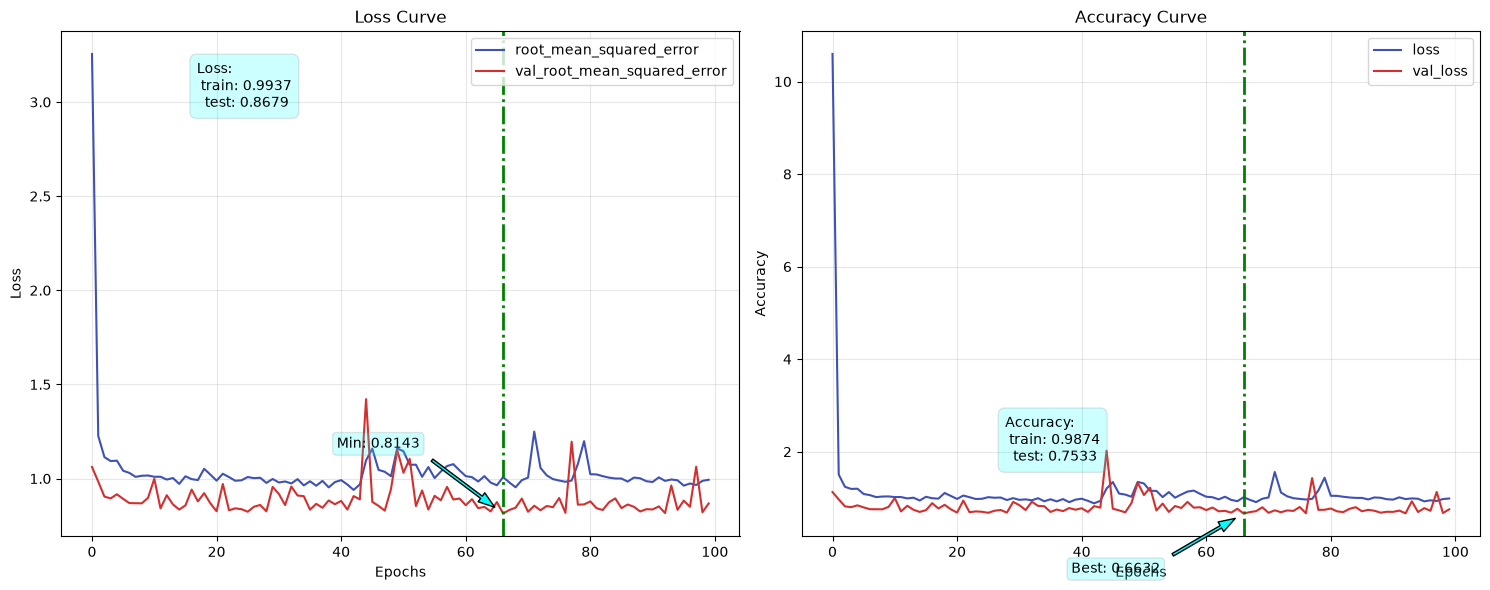

In [30]:
fn_plot_tf_hist(loss_df)

In [31]:
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)
y_pred = np.append(y_train_pred, y_test_pred)

101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


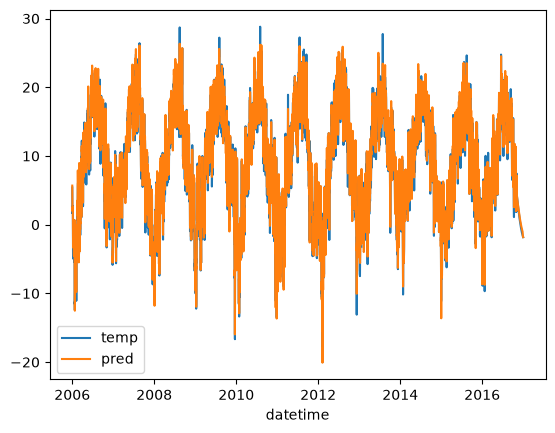

In [32]:
res_df = y_df.copy()
res_df['pred'] = y_pred
res_df['datetime'] = res_df['datetime'].dt.date
ax = res_df.plot(x='datetime', y=['temp','pred'])